# GeoEarthworm — Bedrock Interpolation Workflow

This notebook demonstrates a complete end-to-end workflow using the `GeoEarthworm` package:

1. Import bedrock study data
2. Interpolate bedrock altitude using IDW
3. Save the interpolated result as a GeoTIFF
4. Calculate overburden (surface - bedrock)
5. Visualize all outputs

---

## 0. Imports & Setup

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import TwoSlopeNorm
import rasterio
from rasterio.transform import from_bounds
from rasterio.crs import CRS
from pathlib import Path
import warnings

# Import GeoEarthworm — adjust path if the module lives elsewhere
from geo_earthworm import GeoEarthworm as gew

# Output directory
OUT_DIR = Path("geoearthworm_output")
OUT_DIR.mkdir(exist_ok=True)

print("Imports complete.")
print(f"Output directory: {OUT_DIR.resolve()}")

Imports complete.
Output directory: C:\Users\samue\Desktop\GeoEarthworm\geoearthworm_output



___
## 1. Load in bedrock data

### 1a. Plot point data

In [19]:
# Load data from CSV
lon, lat, bedrock, epsg = gew.load_points_from_csv(
    filepath ='final_wells.csv',
    lon_col='Long',
    lat_col='Lat',
    epsg = 4326,
    bedrock_col='Bk_alt_m'
)

print(f"Loaded {len(lon)} points from CSV")
print(f"Longitude range: {lon.min():.2f} to {lon.max():.2f}")
print(f"Latitude range: {lat.min():.2f} to {lat.max():.2f}")
print(f"Depth range: {bedrock.min():.1f} to {bedrock.max():.1f} m")
print(f"Number of points: {len(lon)}")
print(f"bedrock range: {min(bedrock)} - {max(bedrock)} meters")

Loaded 17698 points from CSV
Longitude range: -71.88 to -71.12
Latitude range: 41.32 to 42.02
Depth range: -113.1 to 243.8 m
Number of points: 17698
bedrock range: -113.0821762 - 243.8029785 meters


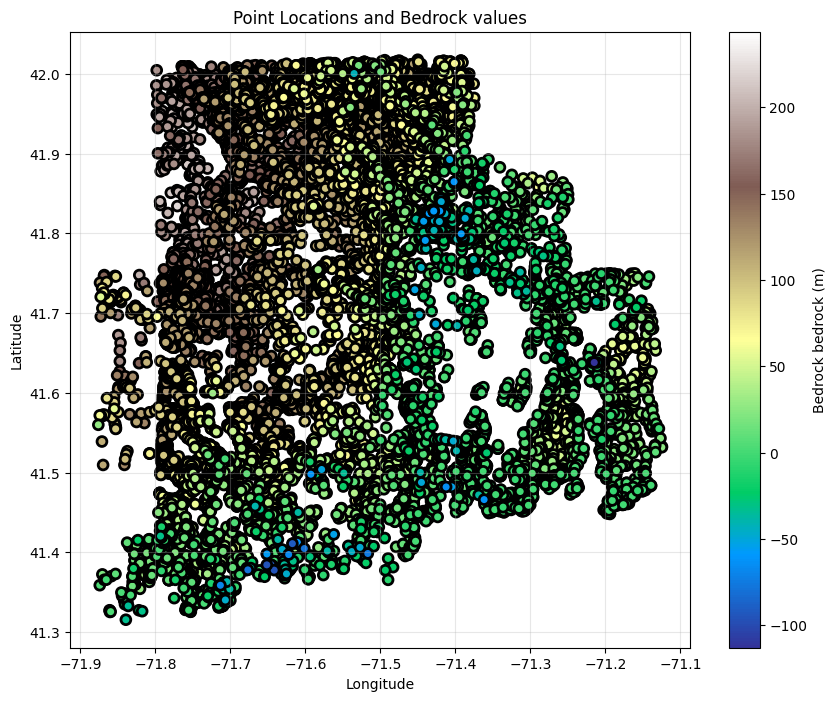

In [20]:
# Visualize borehole locations
plt.figure(figsize=(10, 8))
scatter = plt.scatter(lon, lat, 
                     c=bedrock, cmap='terrain', 
                     s=50, edgecolors='black', linewidths=2)
plt.colorbar(scatter, label='Bedrock bedrock (m)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Point Locations and Bedrock values')
plt.grid(True, alpha=0.3)
plt.show()

---
## 2. Import DEM

In [ ]:
# DEM resolution and grid
DEM_RES = 500   # metres per pixel

dem_cols = int((X_MAX - X_MIN) / DEM_RES)
dem_rows = int((Y_MAX - Y_MIN) / DEM_RES)

dem_x = np.linspace(X_MIN, X_MAX, dem_cols)
dem_y = np.linspace(Y_MAX, Y_MIN, dem_rows)  # top-to-bottom
dem_xx, dem_yy = np.meshgrid(dem_x, dem_y)

norm_xx = (dem_xx - X_MIN) / (X_MAX - X_MIN)
norm_yy = (dem_yy - Y_MIN) / (Y_MAX - Y_MIN)

# True bedrock surface on the DEM grid (same trend as boreholes)
true_bedrock_grid = (
    -30 * norm_xx
    + 40 * norm_yy
    + 20 * np.sin(norm_xx * np.pi * 2)
    + 10 * np.cos(norm_yy * np.pi * 3)
    - 10
)

# Overburden layer: 15–60 m, spatially varying
true_overburden = (
    30
    + 15 * norm_xx
    + 15 * norm_yy
    + 5  * np.sin(norm_xx * np.pi * 4)
    + np.random.default_rng(0).uniform(0, 5, true_bedrock_grid.shape)
)

dem_array = (true_bedrock_grid + true_overburden).astype(np.float32)

print(f"DEM shape: {dem_array.shape}  ({dem_rows} rows × {dem_cols} cols)")
print(f"DEM elevation range: {dem_array.min():.1f}m to {dem_array.max():.1f}m")

# Save DEM as GeoTIFF
dem_path = OUT_DIR / "synthetic_dem.tif"
dem_transform = from_bounds(X_MIN, Y_MIN, X_MAX, Y_MAX, dem_cols, dem_rows)

with rasterio.open(
    dem_path, 'w',
    driver='GTiff',
    height=dem_rows, width=dem_cols,
    count=1,
    dtype=dem_array.dtype,
    crs=CRS.from_epsg(EPSG),
    transform=dem_transform,
    nodata=-9999.0,
    compress='lzw'
) as dst:
    dst.write(dem_array, 1)

print(f"DEM saved to: {dem_path}")

DEM shape: (300, 260)  (300 rows × 260 cols)
DEM elevation range: -7.6m to 92.4m
DEM saved to: geoearthworm_output\synthetic_dem.tif


---
## 3. Initialise GeoEarthworm

Pass the borehole coordinates, bedrock altitude values, CRS, and the DEM path.
Setting `is_altitude=True` tells the class the values are bedrock elevations
(not depths), which controls how depth conversion is handled internally.

In [ ]:
interpolator = GeoEarthworm(
    lon=bh_x,
    lat=bh_y,
    bedrock=bedrock_altitude,
    epsg=EPSG,
    is_altitude=True,
    dem_path=str(dem_path)
)

stats = interpolator.get_statistics()
print("Input borehole statistics:")
for k, v in stats.items():
    print(f"  {k}: {v}")

Input borehole statistics:
  min: -54.69563120721185
  max: 48.14102186227586
  mean: -3.9011651754302465
  std: 25.984850453783356
  count: 120


---
## 4. Interpolate Bedrock Altitude → GeoTIFF

Key parameters:
- `resolution`: grid cell size in CRS units (metres here). 500 m matches the DEM.
- `max_neighbors=12`: only the 12 nearest boreholes influence each cell — large memory saving.
- `power=2`: standard IDW decay. Increase to sharpen local influence.
- `output_depth=False`: we want bedrock *altitude*, not depth.
- `chunk_size=5000`: process 5,000 grid points at a time to keep RAM low.

In [ ]:
BBOX = (X_MIN, Y_MIN, X_MAX, Y_MAX)
RESOLUTION = 500   # metres — match DEM resolution

bedrock_path = OUT_DIR / "bedrock_altitude.tif"

bedrock_grid, bedrock_transform = interpolator.interpolate_to_raster(
    bbox=BBOX,
    resolution=RESOLUTION,
    output_path=str(bedrock_path),
    power=2.0,
    max_neighbors=12,
    smoothing=0.0,
    output_depth=False,
    nodata_value=-9999.0,
    chunk_size=5000
)

# Mask nodata for downstream use
bedrock_grid = np.where(bedrock_grid == -9999.0, np.nan, bedrock_grid)

output_stats = interpolator.get_statistics(bedrock_grid)
print("\nInterpolated bedrock altitude statistics:")
for k, v in output_stats.items():
    print(f"  {k}: {v}")

Raster saved to: geoearthworm_output\bedrock_altitude.tif
Dimensions: 300 rows x 260 cols
Resolution: 500
EPSG: 32619

Interpolated bedrock altitude statistics:
  min: -54.691987531238205
  max: 48.139078836783824
  mean: -4.82040386861396
  std: 24.025331748996564
  count: 78000


### 4a. Verify the GeoTIFF is readable

In [ ]:
with rasterio.open(bedrock_path) as src:
    print(f"File:      {bedrock_path.name}")
    print(f"CRS:       {src.crs}")
    print(f"Shape:     {src.height} rows × {src.width} cols")
    print(f"Transform: {src.transform}")
    print(f"Nodata:    {src.nodata}")
    print(f"Dtype:     {src.dtypes[0]}")

File:      bedrock_altitude.tif
CRS:       EPSG:32619
Shape:     300 rows × 260 cols
Transform: | 500.00, 0.00, 300000.00|
| 0.00,-500.00, 4700000.00|
| 0.00, 0.00, 1.00|
Nodata:    -9999.0
Dtype:     float64


---
## 5. Calculate Overburden

`calculate_overburden` reprojects the DEM to exactly match the bedrock raster
(same CRS, same pixel grid) before subtracting. No manual resampling needed.

In [ ]:
overburden_path = OUT_DIR / "overburden.tif"

overburden_grid, overburden_transform = interpolator.calculate_overburden(
    interpolated_path=str(bedrock_path),
    dem_path=str(dem_path),
    output_path=str(overburden_path),
    nodata_value=-9999.0
)

# Mask nodata
overburden_grid = np.where(overburden_grid == -9999.0, np.nan, overburden_grid)

DEM shape:     (300, 260)
Bedrock shape: (300, 260)
CRS:           EPSG:32619

Overburden statistics:
  min: 22.74m
  max: 70.06m
  mean: 47.32m
  std: 7.34m

Overburden raster saved to: geoearthworm_output\overburden.tif


---
## 6. Visualise Results

Four-panel summary:
- Borehole data
- Interpolated bedrock altitude
- DEM surface
- Calculated overburden

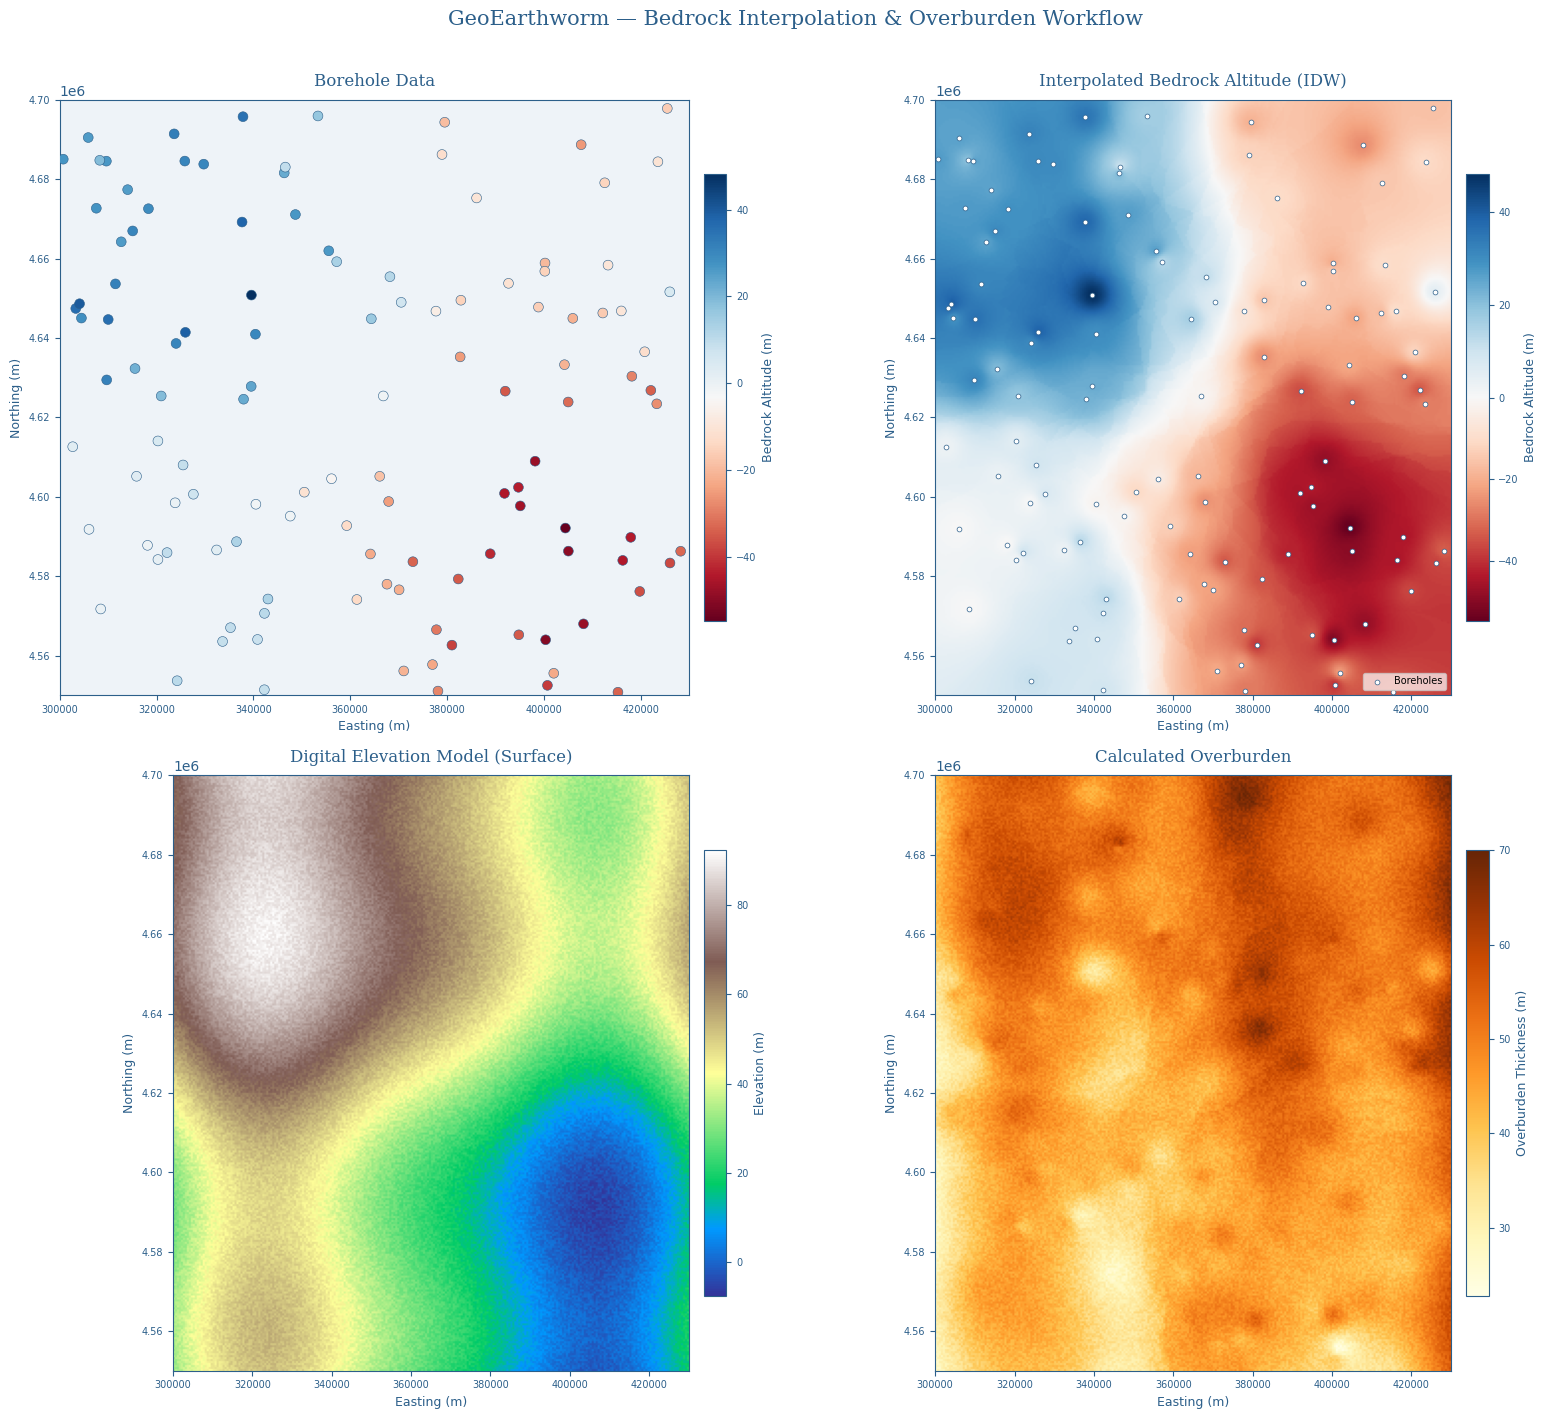

Summary figure saved.


In [ ]:
extent = [X_MIN, X_MAX, Y_MIN, Y_MAX]

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.patch.set_facecolor("white")

TITLE_KW  = dict(fontsize=12, fontfamily="serif", color="#2c5f8a", pad=10)
LABEL_KW  = dict(fontsize=9,  color="#2c5f8a")
CBAR_KW   = dict(shrink=0.75, pad=0.02)

def _style_ax(ax):
    ax.set_facecolor("#eef3f8")
    ax.tick_params(colors="#2c5f8a", labelsize=7)
    ax.set_xlabel("Easting (m)",  **LABEL_KW)
    ax.set_ylabel("Northing (m)", **LABEL_KW)
    for spine in ax.spines.values():
        spine.set_edgecolor("#2c5f8a")

# --- Panel 1: Borehole scatter ---
ax = axes[0, 0]
_style_ax(ax)
sc = ax.scatter(
    bh_x, bh_y, c=bedrock_altitude,
    cmap="RdBu", s=50,
    edgecolors="#2c5f8a", linewidths=0.4, zorder=3
)
cbar = fig.colorbar(sc, ax=ax, **CBAR_KW)
cbar.set_label("Bedrock Altitude (m)", **LABEL_KW)
cbar.ax.tick_params(labelsize=7, colors="#2c5f8a")
cbar.outline.set_edgecolor("#2c5f8a")
ax.set_title("Borehole Data", **TITLE_KW)
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)

# --- Panel 2: Interpolated bedrock ---
ax = axes[0, 1]
_style_ax(ax)
vmin, vmax = np.nanmin(bedrock_grid), np.nanmax(bedrock_grid)
vcenter = 0
norm = TwoSlopeNorm(
    vmin=min(vmin, -0.01),
    vcenter=vcenter,
    vmax=max(vmax,  0.01)
)
im = ax.imshow(
    bedrock_grid, cmap="RdBu", norm=norm,
    extent=extent, origin="upper"
)
cbar = fig.colorbar(im, ax=ax, **CBAR_KW)
cbar.set_label("Bedrock Altitude (m)", **LABEL_KW)
cbar.ax.tick_params(labelsize=7, colors="#2c5f8a")
cbar.outline.set_edgecolor("#2c5f8a")
ax.set_title("Interpolated Bedrock Altitude (IDW)", **TITLE_KW)

# Overlay borehole locations
ax.scatter(bh_x, bh_y, c="white", s=12, edgecolors="#2c5f8a",
           linewidths=0.5, zorder=3, label="Boreholes")
ax.legend(fontsize=7, framealpha=0.7, loc="lower right")

# --- Panel 3: DEM ---
ax = axes[1, 0]
_style_ax(ax)
im = ax.imshow(
    dem_array, cmap="terrain",
    extent=extent, origin="upper"
)
cbar = fig.colorbar(im, ax=ax, **CBAR_KW)
cbar.set_label("Elevation (m)", **LABEL_KW)
cbar.ax.tick_params(labelsize=7, colors="#2c5f8a")
cbar.outline.set_edgecolor("#2c5f8a")
ax.set_title("Digital Elevation Model (Surface)", **TITLE_KW)

# --- Panel 4: Overburden ---
ax = axes[1, 1]
_style_ax(ax)
im = ax.imshow(
    overburden_grid, cmap="YlOrBr",
    vmin=np.nanmin(overburden_grid),
    vmax=np.nanmax(overburden_grid),
    extent=extent, origin="upper"
)
cbar = fig.colorbar(im, ax=ax, **CBAR_KW)
cbar.set_label("Overburden Thickness (m)", **LABEL_KW)
cbar.ax.tick_params(labelsize=7, colors="#2c5f8a")
cbar.outline.set_edgecolor("#2c5f8a")
ax.set_title("Calculated Overburden", **TITLE_KW)

fig.suptitle(
    "GeoEarthworm — Bedrock Interpolation & Overburden Workflow",
    fontsize=15, fontfamily="serif", color="#2c5f8a", y=1.01
)

plt.tight_layout()
plt.savefig(
    OUT_DIR / "workflow_summary.png",
    dpi=200, bbox_inches="tight", facecolor="white"
)
plt.show()
print("Summary figure saved.")

---
## 7. Cross-Section Profile

Extract a west–east transect at the mid-northing to visually verify that
overburden = DEM − bedrock at every pixel.

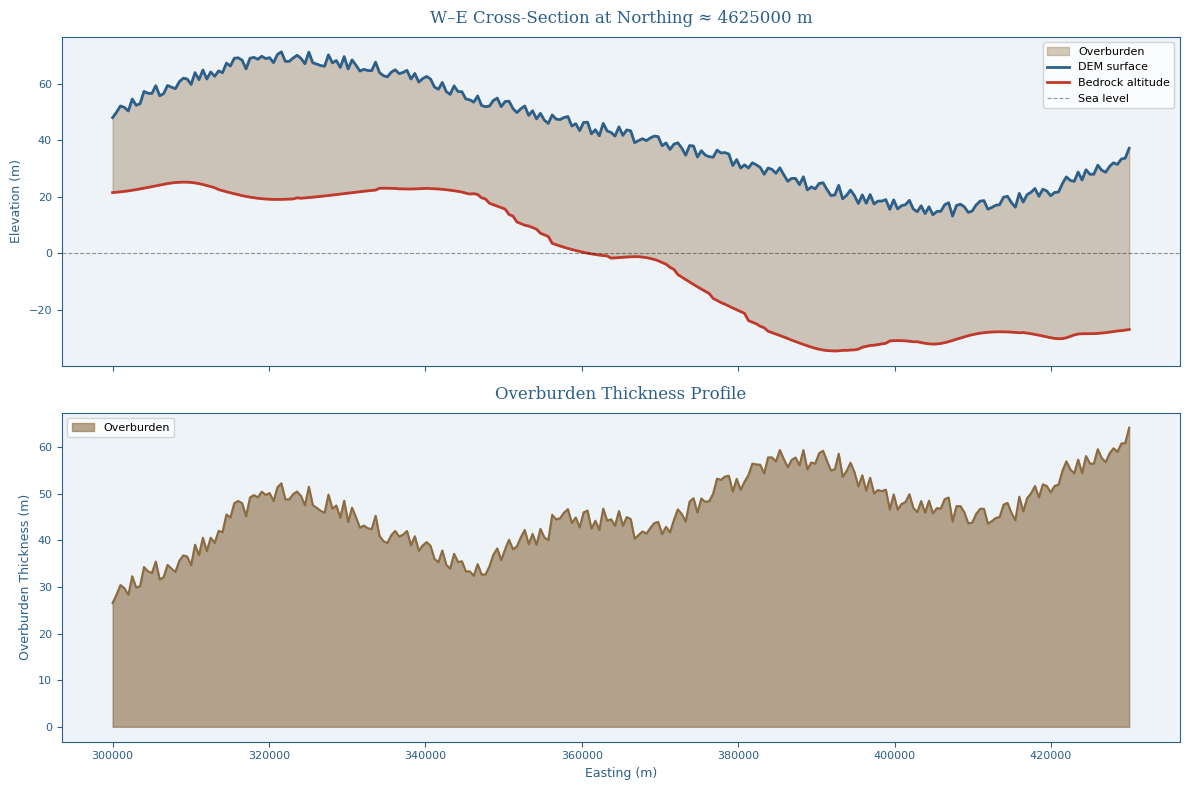

In [ ]:
mid_row = bedrock_grid.shape[0] // 2

# Read DEM resampled to bedrock grid for fair comparison
from rasterio.warp import reproject, Resampling as RS

with rasterio.open(bedrock_path) as ref:
    ref_shape     = (ref.height, ref.width)
    ref_transform = ref.transform
    ref_crs       = ref.crs

with rasterio.open(dem_path) as dem_src:
    dem_aligned = np.full(ref_shape, np.nan, dtype=np.float64)
    reproject(
        source=rasterio.band(dem_src, 1),
        destination=dem_aligned,
        src_transform=dem_src.transform,
        src_crs=dem_src.crs,
        dst_transform=ref_transform,
        dst_crs=ref_crs,
        resampling=RS.bilinear,
        dst_nodata=np.nan
    )

x_profile  = np.linspace(X_MIN, X_MAX, bedrock_grid.shape[1])
dem_row    = dem_aligned[mid_row, :]
bed_row    = bedrock_grid[mid_row, :]
ovrb_row   = overburden_grid[mid_row, :]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
fig.patch.set_facecolor("white")

# Elevation cross-section
ax1.set_facecolor("#eef3f8")
ax1.fill_between(x_profile, bed_row, dem_row, alpha=0.35,
                 color="#8b6c42", label="Overburden")
ax1.plot(x_profile, dem_row,  color="#2c5f8a", lw=2,   label="DEM surface")
ax1.plot(x_profile, bed_row,  color="#c0392b", lw=2,   label="Bedrock altitude")
ax1.axhline(0, color="black", lw=0.8, linestyle="--", alpha=0.4, label="Sea level")
ax1.set_ylabel("Elevation (m)", **LABEL_KW)
ax1.set_title(
    f"W–E Cross-Section at Northing ≈ {Y_MIN + (Y_MAX - Y_MIN) * 0.5:.0f} m",
    **TITLE_KW
)
ax1.legend(fontsize=8, framealpha=0.8)
ax1.tick_params(colors="#2c5f8a", labelsize=8)
for spine in ax1.spines.values():
    spine.set_edgecolor("#2c5f8a")

# Overburden thickness
ax2.set_facecolor("#eef3f8")
ax2.fill_between(x_profile, 0, ovrb_row, color="#8b6c42", alpha=0.6, label="Overburden")
ax2.plot(x_profile, ovrb_row, color="#8b6c42", lw=1.5)
ax2.set_ylabel("Overburden Thickness (m)", **LABEL_KW)
ax2.set_xlabel("Easting (m)", **LABEL_KW)
ax2.set_title("Overburden Thickness Profile", **TITLE_KW)
ax2.legend(fontsize=8, framealpha=0.8)
ax2.tick_params(colors="#2c5f8a", labelsize=8)
for spine in ax2.spines.values():
    spine.set_edgecolor("#2c5f8a")

plt.tight_layout()
plt.savefig(
    OUT_DIR / "cross_section_profile.png",
    dpi=200, bbox_inches="tight", facecolor="white"
)
plt.show()

---
## 8. Output File Summary

In [ ]:
outputs = [
    ("synthetic_boreholes.csv",   "Borehole input data"),
    ("synthetic_dem.tif",         "Synthetic DEM (GeoTIFF, EPSG:32619)"),
    ("bedrock_altitude.tif",      "IDW-interpolated bedrock altitude (GeoTIFF)"),
    ("overburden.tif",            "Calculated overburden thickness (GeoTIFF)"),
    ("01_borehole_locations.png", "Borehole location map"),
    ("workflow_summary.png",      "Four-panel summary figure"),
    ("cross_section_profile.png", "W-E cross-section profile"),
]

print(f"{'File':<40} {'Description':<45} {'Size':>8}")
print("-" * 96)
for fname, desc in outputs:
    fpath = OUT_DIR / fname
    size  = fpath.stat().st_size / 1024 if fpath.exists() else 0
    flag  = "" if fpath.exists() else "  ← MISSING"
    print(f"{fname:<40} {desc:<45} {size:>6.1f} KB{flag}")

File                                     Description                                       Size
------------------------------------------------------------------------------------------------
synthetic_boreholes.csv                  Borehole input data                              6.6 KB
synthetic_dem.tif                        Synthetic DEM (GeoTIFF, EPSG:32619)            340.8 KB
bedrock_altitude.tif                     IDW-interpolated bedrock altitude (GeoTIFF)    739.9 KB
overburden.tif                           Calculated overburden thickness (GeoTIFF)      717.7 KB
01_borehole_locations.png                Borehole location map                          107.2 KB
workflow_summary.png                     Four-panel summary figure                      861.0 KB
cross_section_profile.png                W-E cross-section profile                      224.3 KB
